# Детекция ботов в диалогах. Продвинутый Feature Engineering и отбор признаков

Постановка задачи: генерация расширенного пула признаков, устранение мультиколлинеарности и совместная селекция признаков с подбором гиперпараметров.

Цели этапа:
- извлечение непересекающихся групп признаков: структура, типографика, интерактивность, байесовские шаблоны, tf-idf и SVD
- сохранение полного среза candidate_features и очищенного среза pruned_features в ClickHouse
- устранение мультиколлинеарности при пороге корреляции выше 0.95
- совместный подбор оптимального числа признаков (Top-K) и гиперпараметров в Optuna

In [1]:
import json

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import polars as pl
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold

from project import Reproducibility
from project.features import (
    BaselineHeuristicsView,
    BayesianTemplateView,
    CharTFIDFConfig,
    CharTFIDFView,
    ChatTypographyView,
    DialogueStructureView,
    FeatureStore,
    InteractivityView,
    TextMetricsView,
    TFIDFConfig,
    TFIDFView,
)
from project.infrastructure.clickhouse import FeatureDWH
from project.models.classical import (
    CatBoostSearchConfig,
    CatBoostTrainer,
    ClassicalTrainerConfig,
    LightGBMSearchConfig,
    LightGBMTrainer,
    XGBoostSearchConfig,
    XGBoostTrainer,
)
from project.models.nlp.bayesian import BayesianPhraseTrainer

2026/11/09 21:18:55 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/alex/cu/prod-ml/a.gorobchenko/project/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [2]:
Reproducibility.seed(42)

## Загрузка данных из ClickHouse DWH

выгрузим исходные диалоги и разметку обучающей и тестовой выборок из ClickHouse

In [3]:
dwh = FeatureDWH()

train_dialogs = dwh.raw.load_dialogues_dict("train")
test_dialogs = dwh.raw.load_dialogues_dict("test")
ytrain = dwh.raw.load_labels("train")
ytest = dwh.raw.load_labels("test")

pl.DataFrame(
    {
        "dataset": ["train", "test"],
        "dialogs_count": [len(train_dialogs), len(test_dialogs)],
        "participants_count": [ytrain.height, ytest.height],
        "bot_ratio": [round(float(ytrain["is_bot"].mean()), 4), None],
    }
)

dataset,dialogs_count,participants_count,bot_ratio
str,i64,i64,f64
"""train""",1516,3032,0.408
"""test""",379,758,null


## Извлечение признаков через FeatureStore

соберем расширенный набор признаков из модульных Feature Views без пересечения имен

In [4]:
train_dialogue_list = [train_dialogs[d_id] for d_id in ytrain["dialog_id"].unique(maintain_order=True)]
test_dialogue_list = [test_dialogs[d_id] for d_id in ytest["dialog_id"].unique(maintain_order=True)]

y_train = ytrain["is_bot"].to_numpy().astype(int)
groups = ytrain["dialog_id"].to_numpy()

feature_store = FeatureStore(
    views=[
        BaselineHeuristicsView(),
        DialogueStructureView(),
        TextMetricsView(),
        ChatTypographyView(),
        InteractivityView(),
        BayesianTemplateView(alpha=3.0, min_len=4, min_count=2, n_splits=5),
        TFIDFView(config=TFIDFConfig(max_features=120, ngram_min=1, ngram_max=2, min_df=2, svd_components=15)),
        CharTFIDFView(config=CharTFIDFConfig(max_features=15000, ngram_min=3, ngram_max=5, min_df=2, n_components=35)),
    ]
)

In [5]:
all_feature_names = list(feature_store.default_features)
X_full_tr = feature_store.fit_transform(train_dialogue_list, y=y_train, groups=groups)
X_full_te = feature_store.transform(test_dialogue_list)

pl.DataFrame(
    {
        "feature_view": [v.__class__.__name__ for v in feature_store.views] + ["TOTAL (Zero Duplicates)"],
        "features_count": [len(v.features) for v in feature_store.views] + [len(all_feature_names)],
    }
)

feature_view,features_count
str,i64
"""BaselineHeuristicsView""",32
"""DialogueStructureView""",18
"""TextMetricsView""",13
"""ChatTypographyView""",14
"""InteractivityView""",11
"""BayesianTemplateView""",7
"""TFIDFView""",135
"""CharTFIDFView""",35
"""TOTAL (Zero Duplicates)""",265


## Объединение признакового пространства

составим единую матрицу признаков для обучающей и тестовой выборок

In [6]:
pl.DataFrame(
    {
        "total_candidates": [len(all_feature_names)],
        "train_matrix_shape": [f"{X_full_tr.shape}"],
        "test_matrix_shape": [f"{X_full_te.shape}"],
        "has_nan": [bool(np.isnan(X_full_tr).any())],
    }
)

total_candidates,train_matrix_shape,test_matrix_shape,has_nan
i64,str,str,bool
265,"""(3032, 265)""","""(758, 265)""",false


## Сохранение среза candidate_features в ClickHouse DWH

зарегистрируем полный срез признаков в аналитическом хранилище ClickHouse

In [7]:
df_cands_tr = pl.DataFrame(
    {
        "dialog_id": ytrain["dialog_id"].to_list(),
        "participant_index": ytrain["participant_index"].to_list(),
        **{col: X_full_tr[:, i].tolist() for i, col in enumerate(all_feature_names)},
    }
)
df_cands_te = pl.DataFrame(
    {
        "dialog_id": ytest["dialog_id"].to_list(),
        "participant_index": ytest["participant_index"].to_list(),
        **{col: X_full_te[:, i].tolist() for i, col in enumerate(all_feature_names)},
    }
)

if dwh.features.has_snapshot("candidate_features", "train"):
    dwh.features.drop_snapshot("candidate_features")

dwh.features.save_snapshot(
    snapshot_tag="candidate_features",
    features_df=df_cands_tr,
    dataset_type="train",
    description=f"{len(all_feature_names)} непересекающихся признаков всех Feature Views",
)
dwh.features.save_snapshot(
    snapshot_tag="candidate_features",
    features_df=df_cands_te,
    dataset_type="test",
    description=f"{len(all_feature_names)} непересекающихся признаков всех Feature Views",
)

dwh.features.list_snapshots()

snapshot_id,snapshot_tag,features_count,description,created_at
i64,str,i64,str,datetime[μs]
1,"""baseline_features""",62,"""Базовые эвристики реплик и диа…",2026-11-09 17:16:40
2,"""candidate_features""",265,"""265 непересекающихся признаков…",2026-11-09 18:19:10


## Корреляционный анализ и устранение мультиколлинеарности

найдем и исключим пары признаков с абсолютным коэффициентом корреляции выше 0.95

In [8]:
std = np.std(X_full_tr, axis=0)
non_const = np.where(std > 1e-10)[0]

corr_matrix = np.corrcoef(X_full_tr[:, non_const], rowvar=False)
corr_matrix = np.nan_to_num(corr_matrix, nan=0.0)

drop_rel = set()
for i in range(corr_matrix.shape[0]):
    if i in drop_rel:
        continue
    for j in range(i + 1, corr_matrix.shape[1]):
        if abs(corr_matrix[i, j]) > 0.95:
            drop_rel.add(j)

clean_indices = [non_const[i] for i in range(len(non_const)) if i not in drop_rel]
clean_feature_names = [all_feature_names[i] for i in clean_indices]

X_clean_tr = X_full_tr[:, clean_indices]
X_clean_te = X_full_te[:, clean_indices]
n_clean_features = X_clean_tr.shape[1]

df_pruned_tr = pl.DataFrame(
    {
        "dialog_id": ytrain["dialog_id"].to_list(),
        "participant_index": ytrain["participant_index"].to_list(),
        **{col: X_clean_tr[:, i].tolist() for i, col in enumerate(clean_feature_names)},
    }
)
df_pruned_te = pl.DataFrame(
    {
        "dialog_id": ytest["dialog_id"].to_list(),
        "participant_index": ytest["participant_index"].to_list(),
        **{col: X_clean_te[:, i].tolist() for i, col in enumerate(clean_feature_names)},
    }
)

if dwh.features.has_snapshot("pruned_features", "train"):
    dwh.features.drop_snapshot("pruned_features")

dwh.features.save_snapshot(
    snapshot_tag="pruned_features",
    features_df=df_pruned_tr,
    dataset_type="train",
    description=f"{n_clean_features} очищенных от мультиколлинеарности признаков",
)
dwh.features.save_snapshot(
    snapshot_tag="pruned_features",
    features_df=df_pruned_te,
    dataset_type="test",
    description=f"{n_clean_features} очищенных от мультиколлинеарности признаков",
)

pl.DataFrame(
    {
        "initial_candidates": [len(all_feature_names)],
        "dropped_collinear": [len(all_feature_names) - n_clean_features],
        "clean_retained_features": [n_clean_features],
    }
)

initial_candidates,dropped_collinear,clean_retained_features
i64,i64,i64
265,20,245


## Оценка важности признаков

обучим базовые модели на 5 фолдах для вычисления усредненной важности признаков перед отбором Top-K

In [9]:
y_train = ytrain["is_bot"].to_numpy().astype(int)
groups = ytrain["dialog_id"].to_numpy()

gkf = GroupKFold(n_splits=5)

cb_scores = np.zeros(n_clean_features)
lgb_scores = np.zeros(n_clean_features)
xgb_scores = np.zeros(n_clean_features)

for tr_idx, val_idx in gkf.split(X_clean_tr, y_train, groups):
    # CatBoost
    clf_cb = cb.CatBoostClassifier(
        allow_writing_files=False,
        iterations=300,
        depth=5,
        learning_rate=0.05,
        verbose=False,
        random_seed=42,
        thread_count=4,
    )
    clf_cb.fit(
        X_clean_tr[tr_idx],
        y_train[tr_idx],
        eval_set=(X_clean_tr[val_idx], y_train[val_idx]),
        early_stopping_rounds=30,
    )
    cb_scores += clf_cb.get_feature_importance() / 5.0

    # LightGBM
    clf_lgb = lgb.LGBMClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
        verbose=-1,
        n_jobs=4,
    )
    clf_lgb.fit(
        X_clean_tr[tr_idx],
        y_train[tr_idx],
        eval_X=X_clean_tr[val_idx],
        eval_y=y_train[val_idx],
        callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
    )
    lgb_scores += clf_lgb.feature_importances_ / 5.0

    # XGBoost
    clf_xgb = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        early_stopping_rounds=30,
        random_state=42,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=4,
    )
    clf_xgb.fit(
        X_clean_tr[tr_idx],
        y_train[tr_idx],
        eval_set=[(X_clean_tr[val_idx], y_train[val_idx])],
        verbose=False,
    )
    xgb_scores += clf_xgb.feature_importances_ / 5.0

cb_ranked_indices = np.argsort(cb_scores)[::-1]
lgb_ranked_indices = np.argsort(lgb_scores)[::-1]
xgb_ranked_indices = np.argsort(xgb_scores)[::-1]

pl.DataFrame(
    {
        "model": ["CatBoost", "LightGBM", "XGBoost"],
        "top1_feature": [
            clean_feature_names[cb_ranked_indices[0]],
            clean_feature_names[lgb_ranked_indices[0]],
            clean_feature_names[xgb_ranked_indices[0]],
        ],
        "top2_feature": [
            clean_feature_names[cb_ranked_indices[1]],
            clean_feature_names[lgb_ranked_indices[1]],
            clean_feature_names[xgb_ranked_indices[1]],
        ],
        "top3_feature": [
            clean_feature_names[cb_ranked_indices[2]],
            clean_feature_names[lgb_ranked_indices[2]],
            clean_feature_names[xgb_ranked_indices[2]],
        ],
    }
)

model,top1_feature,top2_feature,top3_feature
str,str,str,str
"""CatBoost""","""is_last_sender""","""log_odds_sum""","""phrase_mean"""
"""LightGBM""","""phrase_mean""","""log_odds_sum""","""fuzzy_echo"""
"""XGBoost""","""is_last_sender""","""phrase_mean""","""lower_rate_self"""


## Подбор признаков и обучение CatBoost

подберем размер ядра Top-K и гиперпараметры CatBoost в Optuna

In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [11]:
search_cfg_cb = CatBoostSearchConfig(
    tune_feature_count=True,
    min_features=10,
    max_features=n_clean_features,
)

trainer_cb = CatBoostTrainer(
    config=ClassicalTrainerConfig(
        run_name="catboost_top_pruned",
        experiment_name="bot-detection",
        description="Совместная оптимизация размера ядра признаков и гиперпараметров CatBoost (300 триалов).",
        n_trials=300,
        patience=50,
        dataset_name="pruned_features",
    ),
    search_config=search_cfg_cb,
)

tuning_cb = trainer_cb.tune(
    X=X_clean_tr,
    y=y_train,
    groups=groups,
    feature_ranking_indices=cb_ranked_indices,
)

best_k_cb = tuning_cb.optimal_features_count
study_cb = tuning_cb.study

result_cb = trainer_cb.fit(
    X_train=X_clean_tr,
    y_train=y_train,
    groups=groups,
    X_test=X_clean_te,
    dialog_ids_train=ytrain["dialog_id"].to_numpy(),
    participant_indices_train=ytrain["participant_index"].to_numpy(),
    dialog_ids_test=ytest["dialog_id"].to_numpy(),
    participant_indices_test=ytest["participant_index"].to_numpy(),
    test_ids=ytest["ID"].to_numpy(),
    feature_names=clean_feature_names,
    feature_ranking_indices=cb_ranked_indices,
)

dwh.predictions.save_predictions(
    run_id=result_cb.run_id,
    run_name="catboost_top_pruned",
    dataset_split="train_oof",
    dialog_ids=ytrain["dialog_id"].to_numpy(),
    participant_indices=ytrain["participant_index"].to_numpy(),
    prob_bot=result_cb.oof_raw,
    prob_bot_calibrated=result_cb.oof_calibrated,
    is_bot=y_train,
)
dwh.predictions.save_predictions(
    run_id=result_cb.run_id,
    run_name="catboost_top_pruned",
    dataset_split="test",
    dialog_ids=ytest["dialog_id"].to_numpy(),
    participant_indices=ytest["participant_index"].to_numpy(),
    prob_bot=result_cb.test_raw,
    prob_bot_calibrated=result_cb.test_calibrated,
)

/home/alex/cu/prod-ml/a.gorobchenko/project/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run catboost_top_pruned at: http://127.0.0.1:5000/#/experiments/7/runs/297a76d061614077955c19742d835d0a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/7


758

## Подбор признаков и обучение LightGBM

подберем размер ядра Top-K и гиперпараметры LightGBM в Optuna

In [12]:
search_cfg_lgb = LightGBMSearchConfig(
    tune_feature_count=True,
    min_features=10,
    max_features=n_clean_features,
)

trainer_lgb = LightGBMTrainer(
    config=ClassicalTrainerConfig(
        run_name="lightgbm_top_pruned",
        experiment_name="bot-detection",
        description="Совместная оптимизация размера ядра признаков и гиперпараметров LightGBM (300 триалов).",
        n_trials=300,
        patience=50,
        dataset_name="pruned_features",
    ),
    search_config=search_cfg_lgb,
)

tuning_lgb = trainer_lgb.tune(
    X=X_clean_tr,
    y=y_train,
    groups=groups,
    feature_ranking_indices=lgb_ranked_indices,
)

best_m_lgb = tuning_lgb.optimal_features_count
study_lgb = tuning_lgb.study

result_lgb = trainer_lgb.fit(
    X_train=X_clean_tr,
    y_train=y_train,
    groups=groups,
    X_test=X_clean_te,
    dialog_ids_train=ytrain["dialog_id"].to_numpy(),
    participant_indices_train=ytrain["participant_index"].to_numpy(),
    dialog_ids_test=ytest["dialog_id"].to_numpy(),
    participant_indices_test=ytest["participant_index"].to_numpy(),
    test_ids=ytest["ID"].to_numpy(),
    feature_names=clean_feature_names,
    feature_ranking_indices=lgb_ranked_indices,
)

dwh.predictions.save_predictions(
    run_id=result_lgb.run_id,
    run_name="lightgbm_top_pruned",
    dataset_split="train_oof",
    dialog_ids=ytrain["dialog_id"].to_numpy(),
    participant_indices=ytrain["participant_index"].to_numpy(),
    prob_bot=result_lgb.oof_raw,
    prob_bot_calibrated=result_lgb.oof_calibrated,
    is_bot=y_train,
)
dwh.predictions.save_predictions(
    run_id=result_lgb.run_id,
    run_name="lightgbm_top_pruned",
    dataset_split="test",
    dialog_ids=ytest["dialog_id"].to_numpy(),
    participant_indices=ytest["participant_index"].to_numpy(),
    prob_bot=result_lgb.test_raw,
    prob_bot_calibrated=result_lgb.test_calibrated,
)

/home/alex/cu/prod-ml/a.gorobchenko/project/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run lightgbm_top_pruned at: http://127.0.0.1:5000/#/experiments/7/runs/41937fb970af4072b80ea3622b00f9ad
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/7


758

## Подбор признаков и обучение XGBoost

подберем размер ядра Top-K и гиперпараметры XGBoost в Optuna

In [13]:
search_cfg_xgb = XGBoostSearchConfig(
    tune_feature_count=True,
    min_features=10,
    max_features=n_clean_features,
)

trainer_xgb = XGBoostTrainer(
    config=ClassicalTrainerConfig(
        run_name="xgboost_top_pruned",
        experiment_name="bot-detection",
        description="Совместная оптимизация размера ядра признаков и гиперпараметров XGBoost (300 триалов).",
        n_trials=300,
        patience=50,
        dataset_name="pruned_features",
    ),
    search_config=search_cfg_xgb,
)

tuning_xgb = trainer_xgb.tune(
    X=X_clean_tr,
    y=y_train,
    groups=groups,
    feature_ranking_indices=xgb_ranked_indices,
)

best_p_xgb = tuning_xgb.optimal_features_count
study_xgb = tuning_xgb.study

result_xgb = trainer_xgb.fit(
    X_train=X_clean_tr,
    y_train=y_train,
    groups=groups,
    X_test=X_clean_te,
    dialog_ids_train=ytrain["dialog_id"].to_numpy(),
    participant_indices_train=ytrain["participant_index"].to_numpy(),
    dialog_ids_test=ytest["dialog_id"].to_numpy(),
    participant_indices_test=ytest["participant_index"].to_numpy(),
    test_ids=ytest["ID"].to_numpy(),
    feature_names=clean_feature_names,
    feature_ranking_indices=xgb_ranked_indices,
)

dwh.predictions.save_predictions(
    run_id=result_xgb.run_id,
    run_name="xgboost_top_pruned",
    dataset_split="train_oof",
    dialog_ids=ytrain["dialog_id"].to_numpy(),
    participant_indices=ytrain["participant_index"].to_numpy(),
    prob_bot=result_xgb.oof_raw,
    prob_bot_calibrated=result_xgb.oof_calibrated,
    is_bot=y_train,
)
dwh.predictions.save_predictions(
    run_id=result_xgb.run_id,
    run_name="xgboost_top_pruned",
    dataset_split="test",
    dialog_ids=ytest["dialog_id"].to_numpy(),
    participant_indices=ytest["participant_index"].to_numpy(),
    prob_bot=result_xgb.test_raw,
    prob_bot_calibrated=result_xgb.test_calibrated,
)

/home/alex/cu/prod-ml/a.gorobchenko/project/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run xgboost_top_pruned at: http://127.0.0.1:5000/#/experiments/7/runs/4b925c4750c14af199b39b50a8934fb3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/7


758

## Сравнительный анализ результатов оптимизации

сравним динамику LogLoss от числа отобранных признаков и зафиксируем лучшие наборы в MLflow

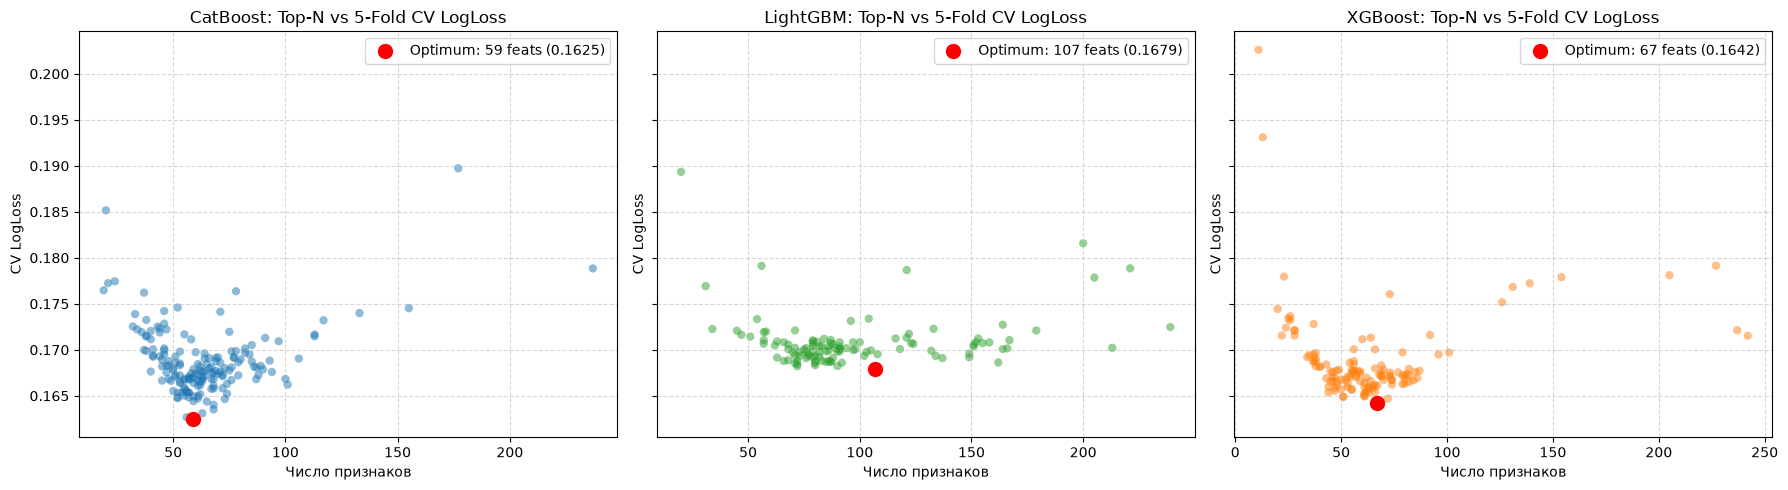

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
studies = [
    (study_cb, "top_k", "CatBoost", axes[0], "#1f77b4", best_k_cb),
    (study_lgb, "top_m", "LightGBM", axes[1], "#2ca02c", best_m_lgb),
    (study_xgb, "top_p", "XGBoost", axes[2], "#ff7f0e", best_p_xgb),
]
for study, param_name, title, ax, col, best_val in studies:
    k_vals = [t.params[param_name] for t in study.trials if t.value is not None]
    scores = [t.value for t in study.trials if t.value is not None]
    ax.scatter(k_vals, scores, alpha=0.5, color=col, edgecolors="none")
    ax.scatter(
        [best_val],
        [study.best_value],
        color="red",
        s=100,
        zorder=5,
        label=f"Optimum: {best_val} feats ({study.best_value:.4f})",
    )
    ax.set_title(f"{title}: Top-N vs 5-Fold CV LogLoss")
    ax.set_xlabel("Число признаков")
    ax.set_ylabel("CV LogLoss")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()